# Dự đoán giá RAM DDR5 bằng thuật toán SVR

Notebook sử dụng **3 bộ dữ liệu CSV**: dữ liệu quan sát giá bán lẻ, dữ liệu RAM eBay và dữ liệu CostInflation.

**Quy trình:** đọc 3 file → chuẩn hóa/gộp dữ liệu → trích xuất đặc trưng → chia train/test theo nhóm sản phẩm → tiền xử lý → huấn luyện SVR → đánh giá tổng thể và theo từng nguồn → biểu đồ → lưu mô hình và dự đoán.

> Lưu ý: dữ liệu được gộp để huấn luyện một mô hình SVR chung. Kết quả đánh giá theo từng nguồn giúp so sánh mô hình trên ba nguồn dữ liệu. File A có trạng thái `discovery_only`, nên kết quả cần được hiểu theo chất lượng và trạng thái của dữ liệu nguồn.

## 1. Thư viện và cấu hình

In [2]:
import os
import re
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVR

%matplotlib inline
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

RANDOM_STATE = 42
MAX_ROWS_FOR_SVR = 6000  # SVR kernel RBF tốn tài nguyên; giới hạn mẫu để chạy ổn định

HERE = Path.cwd()
DATA_DIR = Path(os.environ.get("DATA_DIR", HERE))
RESULTS_DIR = HERE / "results"
RESULTS_DIR.mkdir(exist_ok=True)

FILE_A = DATA_DIR / "ram-price-observations.csv"
FILE_B = DATA_DIR / "ram_pricing_intelligence_2026.csv"
if not FILE_B.exists():
    FILE_B = DATA_DIR / "ram_pricing_intelligence_2026(1).csv"
FILE_C = DATA_DIR / "costinflation-ddr5-ram-retail-prices-raw-2026-07-13-to-2026-08-10.csv"

for f in [FILE_A, FILE_B, FILE_C]:
    if not f.exists():
        raise FileNotFoundError(
            f"Không tìm thấy file: {f}\n"
            "Hãy đặt cả 3 file CSV cùng thư mục với notebook, "
            "hoặc sửa DATA_DIR cho đúng."
        )

print("Đã tìm thấy đủ 3 file dữ liệu.")
print("Thư mục dữ liệu:", DATA_DIR)
print("Thư mục lưu kết quả:", RESULTS_DIR)

Đã tìm thấy đủ 3 file dữ liệu.
Thư mục dữ liệu: d:\DPYTHONSVR
Thư mục lưu kết quả: d:\DPYTHONSVR\results


## 2. Đọc 3 bộ dữ liệu CSV

In [3]:
a = pd.read_csv(FILE_A)
b = pd.read_csv(FILE_B)
c = pd.read_csv(FILE_C)

print("A - ram-price-observations:", a.shape)
print("B - ram_pricing_intelligence:", b.shape)
print("C - costinflation DDR5:", c.shape)

display(a.head(3))
display(b.head(3))
display(c.head(3))

A - ram-price-observations: (414, 9)
B - ram_pricing_intelligence: (2899, 17)
C - costinflation DDR5: (19705, 16)


,capture_date_utc,product_id,product_label,kit_capacity_gb,title,seller,price_usd,usd_per_gb,verification_status
0,2026-08-12,corsair-dominator-titanium-6000c30,Corsair Dominator Titanium 32GB (2x16GB) DDR5-...,32,CORSAIR Dominator Titanium 32GB (2 x 16GB) DDR...,Newegg.com,649.99,20.312,discovery_only
1,2026-08-12,corsair-dominator-titanium-6000c30,Corsair Dominator Titanium 32GB (2x16GB) DDR5-...,32,CORSAIR Dominator Titanium 32GB (2 x 16GB) DDR...,Newegg.com,649.99,20.312,discovery_only
2,2026-08-12,corsair-vengeance-6000c30,Corsair Vengeance 32GB (2x16GB) DDR5-6000 CL30,32,Corsair CMK32GX5M2B6000C30 VENGEANCE DDR5 32GB...,Central Computers,529.99,16.562,discovery_only


,ram_generation,brand,seller_id,condition,title,capacity_gb,bus_speed_mhz,unit_type,price,wasPrice,available,sold,itemLocation,lastUpdated,mpn,type,is_bulk_server
0,DDR4,SK hynix,Seller_0001,Used,SK Hynix 64GB 4DRx4 PC4-2400T DDR4 ECC Server ...,64.0,2400.0,Single,229.00,NaN,6.0,2.0,"Lakeville, Minnesota, United States",2026-04-24 21:22:14,HMAA8GL7MMR4NUH,DDR4 SDRAM,1
1,DDR4,A-Tech,Seller_0002,New,A-Tech 32GB 2x 16GB PC4-21300 Laptop SODIMM 26...,32.0,2666.0,Dual Kit,231.98,NaN,10.0,1728.0,"Columbus, Ohio, United States",2026-04-20 10:40:28,AT16G2D4S2666ND8N12V,DDR4 SDRAM,0
2,DDR4,Crucial,Seller_0003,Used,16GB Crucial Micron DDR4-2133 PC4-17000 RDIMM ...,16.0,2133.0,Single,57.99,NaN,8.0,28.0,"Las Vegas, Nevada, United States",2026-04-24 20:40:30,"CT16G4RFD4213, CT16G4RFD4213.36FA2, CT16G4RFD4...",DDR4 SDRAM,1


,series_id,series_title,canonical_url,geography_type,geography_id,geography_label,observed_date,product_name,quantity_value,quantity_unit,quantity_name,price_amount,currency_code,normalized_price_amount,normalized_quantity_value,normalized_quantity_unit
0,ddr5_memory,DDR5 RAM,https://costinflation.com/indices/ddr5-ram-pri...,postal_code,11385,"New York, NY - Ridgewood/Glendale",2026-07-13,A-Tech 16GB DDR5 5600MHz PC5-44800 CL46 SODIMM...,16,gigabytes,16 gigabytes,230.93,USD,14.4331,1,gigabytes
1,ddr5_memory,DDR5 RAM,https://costinflation.com/indices/ddr5-ram-pri...,postal_code,11385,"New York, NY - Ridgewood/Glendale",2026-07-13,Acer Predator Vesta II RGB DDR5 RAM 32GB (16GB...,32,gigabytes,32 gigabytes,437.99,USD,13.6872,1,gigabytes
2,ddr5_memory,DDR5 RAM,https://costinflation.com/indices/ddr5-ram-pri...,postal_code,11385,"New York, NY - Ridgewood/Glendale",2026-07-13,Biwin Black Opal DW100 DDR5 RGB RAM 48GB (24GB...,48,gigabytes,48 gigabytes,529.99,USD,11.0415,1,gigabytes


## 3. Chuẩn hóa và gộp 3 nguồn dữ liệu
Đưa các nguồn về những cột chung: `source`, `title`, `capacity_gb`, `price`, `usd_per_gb`, `condition`, `speed_hint`.

In [4]:
# Nguồn A: giá quan sát bán lẻ. usd_per_gb đã có sẵn trong file.
df_a = pd.DataFrame({
    "source": "A_retail",
    "title": a["title"].astype(str),
    "capacity_gb": pd.to_numeric(a["kit_capacity_gb"], errors="coerce"),
    "price": pd.to_numeric(a["price_usd"], errors="coerce"),
    "usd_per_gb": pd.to_numeric(a["usd_per_gb"], errors="coerce"),
    "condition": "New",
    "speed_hint": np.nan,
})

# Nguồn B: chỉ lấy RAM DDR5 không phải hàng bulk/server.
b5 = b[
    (b["ram_generation"].astype(str).str.upper() == "DDR5")
    & (pd.to_numeric(b["is_bulk_server"], errors="coerce").fillna(0) == 0)
    & (b["unit_type"].astype(str).str.lower() != "bulk")
].copy()
b5["capacity_gb"] = pd.to_numeric(b5["capacity_gb"], errors="coerce")
b5["price"] = pd.to_numeric(b5["price"], errors="coerce")
b5 = b5.dropna(subset=["capacity_gb", "price"])
b5 = b5[(b5["capacity_gb"] > 0) & (b5["price"] > 0)]

df_b = pd.DataFrame({
    "source": "B_ebay",
    "title": b5["title"].astype(str),
    "capacity_gb": b5["capacity_gb"],
    "price": b5["price"],
    "usd_per_gb": b5["price"] / b5["capacity_gb"],
    "condition": b5["condition"].fillna("Unknown").astype(str),
    "speed_hint": pd.to_numeric(b5["bus_speed_mhz"], errors="coerce"),
})

# Nguồn C: giá đã chuẩn hóa theo GB trong normalized_price_amount.
c2 = c.copy()
c2["quantity_value"] = pd.to_numeric(c2["quantity_value"], errors="coerce")
c2["price_amount"] = pd.to_numeric(c2["price_amount"], errors="coerce")
c2["normalized_price_amount"] = pd.to_numeric(c2["normalized_price_amount"], errors="coerce")
c2 = c2[
    (c2["quantity_value"] > 0)
    & (c2["normalized_price_amount"] > 0)
    & (c2["currency_code"].astype(str).str.upper() == "USD")
].copy()

df_c = pd.DataFrame({
    "source": "C_costinflation",
    "title": c2["product_name"].astype(str),
    "capacity_gb": c2["quantity_value"],
    "price": c2["price_amount"],
    "usd_per_gb": c2["normalized_price_amount"],
    "condition": "New",
    "speed_hint": np.nan,
})

df = pd.concat([df_a, df_b, df_c], ignore_index=True)
df["title"] = df["title"].fillna("").astype(str)
df["condition"] = df["condition"].fillna("Unknown").astype(str)
df["capacity_gb"] = pd.to_numeric(df["capacity_gb"], errors="coerce")
df["usd_per_gb"] = pd.to_numeric(df["usd_per_gb"], errors="coerce")

df = df.dropna(subset=["capacity_gb", "usd_per_gb"])
df = df[(df["capacity_gb"] > 0) & (df["usd_per_gb"] > 0)]
print("Số dòng sau khi gộp:", len(df))
print("\nSố dòng theo nguồn:")
display(df["source"].value_counts().rename_axis("source").to_frame("rows"))
display(df.head())

Số dòng sau khi gộp: 21473

Số dòng theo nguồn:


,rows
source,
C_costinflation,19704
B_ebay,1355
A_retail,414


,source,title,capacity_gb,price,usd_per_gb,condition,speed_hint
0,A_retail,CORSAIR Dominator Titanium 32GB (2 x 16GB) DDR...,32.0,649.99,20.312,New,NaN
1,A_retail,CORSAIR Dominator Titanium 32GB (2 x 16GB) DDR...,32.0,649.99,20.312,New,NaN
2,A_retail,Corsair CMK32GX5M2B6000C30 VENGEANCE DDR5 32GB...,32.0,529.99,16.562,New,NaN
3,A_retail,CORSAIR - Vengeance 32GB (2 x 16GB) 288-Pin PC...,32.0,539.99,16.875,New,NaN
4,A_retail,CORSAIR Vengeance 32GB (2 x 16GB) 288-Pin PC R...,32.0,539.99,16.875,New,NaN


## 4. Trích xuất đặc trưng từ tên sản phẩm
Dùng Regex để lấy hãng, tốc độ bus, CAS latency, số thanh RAM, loại SO-DIMM, RGB và ECC/server.

In [5]:
BRANDS = [
    "Corsair", "G.Skill", "Kingston", "Crucial", "Micron", "TEAMGROUP",
    "T-Force", "Patriot", "Samsung", "SK hynix", "A-Tech", "Acer",
    "Biwin", "ADATA", "XPG", "Lexar", "PNY", "OLOy", "Mushkin",
    "Silicon Power", "Netac", "Thermaltake", "Gigabyte", "ASUS", "MSI"
]

def find_brand(title):
    t = str(title).lower().replace(" ", "").replace("-", "").replace(".", "")
    for brand in BRANDS:
        key = brand.lower().replace(" ", "").replace("-", "").replace(".", "")
        if key in t:
            return brand
    if "hynix" in t:
        return "SK hynix"
    if "gskill" in t or "tridentz" in t:
        return "G.Skill"
    return "Other"

def find_speed(row):
    if pd.notna(row["speed_hint"]) and row["speed_hint"] > 0:
        return float(row["speed_hint"])
    t = str(row["title"])
    m = re.search(r"\b([3-9]\d{3})\s*(?:MHz|MT/s|MTs)?\b", t, flags=re.I)
    if m:
        return float(m.group(1))
    m = re.search(r"B(\d{4})C\d{2}", t, flags=re.I)
    return float(m.group(1)) if m else np.nan

def find_cl(title):
    t = str(title)
    m = re.search(r"\bCL\s?-?(\d{2})\b", t, flags=re.I)
    if m:
        return float(m.group(1))
    m = re.search(r"\b(\d{2})-\d{2}-\d{2}-\d{2,3}\b", t)
    if m:
        return float(m.group(1))
    m = re.search(r"B\d{4}C(\d{2})", t, flags=re.I)
    return float(m.group(1)) if m else np.nan

def find_sticks(title):
    m = re.search(r"\(?\b(\d)\s*[xX]\s*\d+\s*GB", str(title))
    return int(m.group(1)) if m else 1

df["brand"] = df["title"].apply(find_brand)
df["speed_mhz"] = df.apply(find_speed, axis=1)
df["cas_latency"] = df["title"].apply(find_cl)
df["num_sticks"] = df["title"].apply(find_sticks)
df["is_sodimm"] = df["title"].str.contains(
    r"SO-?DIMM|laptop|notebook", case=False, regex=True
).astype(int)
df["has_rgb"] = df["title"].str.contains("RGB", case=False).astype(int)
df["is_ecc_server"] = df["title"].str.contains(
    r"ECC|RDIMM|registered|server", case=False, regex=True
).astype(int)

# Bỏ hàng hỏng/không sử dụng được nếu có.
df = df[~df["condition"].str.lower().isin(
    ["for parts or not working", "parts only", "not working"]
)].copy()

# Cắt ngoại lệ quá cực đoan để giảm ảnh hưởng đến mô hình.
q_low, q_high = df["usd_per_gb"].quantile([0.005, 0.995])
df = df[df["usd_per_gb"].between(q_low, q_high)].reset_index(drop=True)

print("Dữ liệu sau làm sạch:", df.shape)
display(df[["source", "brand", "capacity_gb", "speed_mhz",
            "cas_latency", "num_sticks", "usd_per_gb"]].head())

Dữ liệu sau làm sạch: (21268, 14)


,source,brand,capacity_gb,speed_mhz,cas_latency,num_sticks,usd_per_gb
0,A_retail,Corsair,32.0,6000.0,30.0,2,20.312
1,A_retail,Corsair,32.0,6000.0,30.0,2,20.312
2,A_retail,Corsair,32.0,6000.0,30.0,2,16.562
3,A_retail,Corsair,32.0,6000.0,30.0,2,16.875
4,A_retail,Corsair,32.0,6000.0,NaN,2,16.875


## 5. Khám phá dữ liệu (EDA)

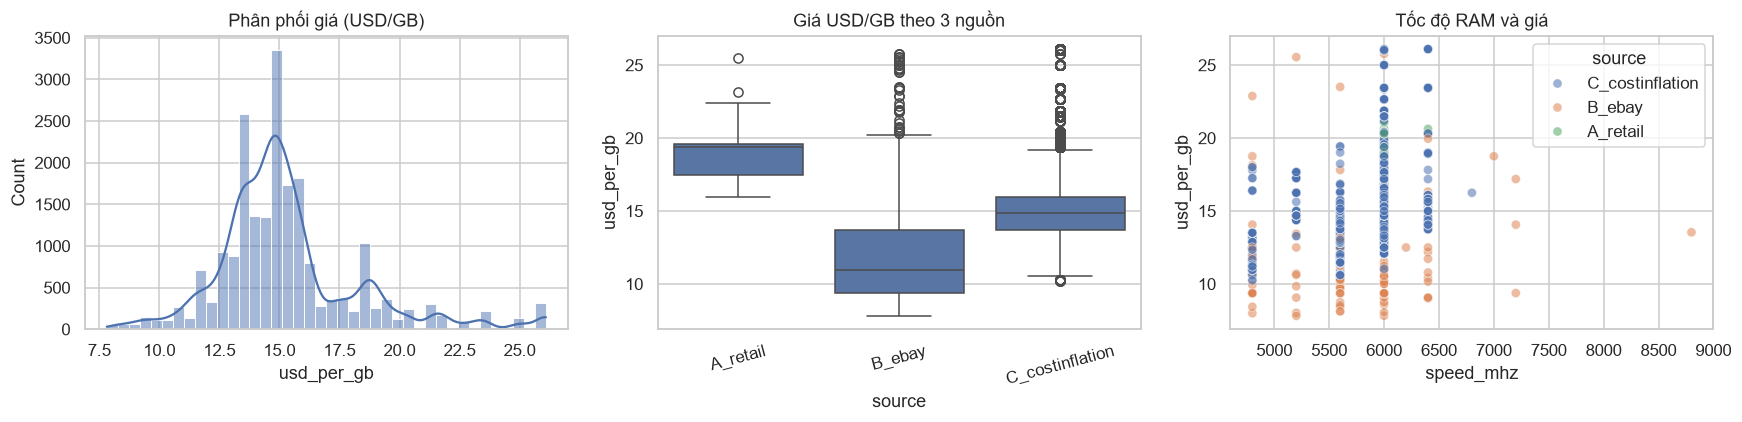

Giá trị thiếu:


,missing
source,0
title,0
capacity_gb,0
price,0
usd_per_gb,0
condition,0
speed_hint,20163
brand,0
speed_mhz,106
cas_latency,2156


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(df["usd_per_gb"], bins=40, kde=True, ax=axes[0])
axes[0].set_title("Phân phối giá (USD/GB)")

sns.boxplot(data=df, x="source", y="usd_per_gb", ax=axes[1])
axes[1].set_title("Giá USD/GB theo 3 nguồn")
axes[1].tick_params(axis="x", rotation=15)

plot_df = df.sample(min(2500, len(df)), random_state=RANDOM_STATE)
sns.scatterplot(data=plot_df, x="speed_mhz", y="usd_per_gb",
                hue="source", alpha=0.55, ax=axes[2])
axes[2].set_title("Tốc độ RAM và giá")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "01_eda_3_sources.png", dpi=120)
plt.show()

print("Giá trị thiếu:")
display(df.isna().sum().to_frame("missing"))

## 6. Chia Train/Test theo nhóm sản phẩm
Các dòng có cùng tên sản phẩm được giữ cùng một phía train hoặc test để hạn chế rò rỉ dữ liệu.

In [7]:
TARGET = "usd_per_gb"
NUM_COLS = [
    "capacity_gb", "speed_mhz", "cas_latency", "num_sticks",
    "is_sodimm", "has_rgb", "is_ecc_server"
]
CAT_COLS = ["brand", "source", "condition"]

# SVR RBF có thể chậm khi số dòng quá lớn. Giữ lại tối đa 6.000 dòng,
# lấy mẫu theo tỷ lệ nguồn để cả ba nguồn đều được đại diện.
if len(df) > MAX_ROWS_FOR_SVR:
    sampled_parts = []
    for source, part in df.groupby("source"):
        n = max(1, round(MAX_ROWS_FOR_SVR * len(part) / len(df)))
        sampled_parts.append(part.sample(n=min(n, len(part)), random_state=RANDOM_STATE))
    df_model = pd.concat(sampled_parts, ignore_index=True)
    if len(df_model) > MAX_ROWS_FOR_SVR:
        df_model = df_model.sample(MAX_ROWS_FOR_SVR, random_state=RANDOM_STATE)
else:
    df_model = df.copy()

X = df_model[NUM_COLS + CAT_COLS]
y = df_model[TARGET]
groups = df_model["title"].str.lower().str.replace(r"\s+", " ", regex=True).str.strip()

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
train_idx, test_idx = next(gss.split(X, y, groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
source_test = df_model["source"].iloc[test_idx].reset_index(drop=True)

print(f"Tổng mẫu dùng cho SVR: {len(df_model)}")
print(f"Train: {len(X_train)} | Test: {len(X_test)}")
print("\nPhân bố nguồn trong tập train:")
display(df_model.iloc[train_idx]["source"].value_counts().to_frame("rows"))
print("\nPhân bố nguồn trong tập test:")
display(df_model.iloc[test_idx]["source"].value_counts().to_frame("rows"))

Tổng mẫu dùng cho SVR: 6000
Train: 5190 | Test: 810

Phân bố nguồn trong tập train:


,rows
source,
C_costinflation,4830
B_ebay,270
A_retail,90



Phân bố nguồn trong tập test:


,rows
source,
C_costinflation,705
B_ebay,78
A_retail,27


## 7. Pipeline tiền xử lý và mô hình SVR
SVR sử dụng RBF. Đặc trưng số được điền giá trị thiếu và chuẩn hóa; đặc trưng phân loại được One-Hot Encoding. Biến mục tiêu được biến đổi log để giảm độ lệch giá.

In [8]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, NUM_COLS),
    ("cat", categorical_transformer, CAT_COLS)
])

svr_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("svr", SVR(kernel="rbf", C=100, epsilon=0.1, gamma="scale"))
])

model = TransformedTargetRegressor(
    regressor=svr_pipeline,
    func=np.log1p,
    inverse_func=np.expm1
)

print("Đã khởi tạo pipeline SVR. Chưa huấn luyện ở bước này.")

Đã khởi tạo pipeline SVR. Chưa huấn luyện ở bước này.


## 8. Huấn luyện mô hình SVR

In [9]:
print("Đang huấn luyện mô hình SVR...")
model.fit(X_train, y_train)
print("Hoàn tất huấn luyện SVR.")

Đang huấn luyện mô hình SVR...
Hoàn tất huấn luyện SVR.


## 9. Dự đoán và đánh giá mô hình
Đánh giá bằng MAE, MSE, RMSE và R². Ngoài kết quả tổng thể, notebook còn hiển thị kết quả riêng trên từng nguồn dữ liệu.

In [10]:
y_pred = model.predict(X_test)
y_pred = np.maximum(y_pred, 0)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("===== KẾT QUẢ SVR - TOÀN BỘ TẬP TEST =====")
print(f"MAE  : {mae:.4f} USD/GB")
print(f"MSE  : {mse:.4f}")
print(f"RMSE : {rmse:.4f} USD/GB")
print(f"R²   : {r2:.4f}")

results_by_source = []
eval_df = pd.DataFrame({
    "source": source_test.to_numpy(),
    "actual": y_test.to_numpy(),
    "predicted": y_pred
})
for source, part in eval_df.groupby("source"):
    if len(part) < 2:
        continue
    results_by_source.append({
        "source": source,
        "n_test": len(part),
        "MAE": mean_absolute_error(part["actual"], part["predicted"]),
        "RMSE": np.sqrt(mean_squared_error(part["actual"], part["predicted"])),
        "R2": r2_score(part["actual"], part["predicted"])
    })

metrics_source = pd.DataFrame(results_by_source)
print("\n===== KẾT QUẢ THEO TỪNG NGUỒN DỮ LIỆU =====")
display(metrics_source.round(4))
metrics_source.to_csv(RESULTS_DIR / "svr_metrics_by_source.csv", index=False)

===== KẾT QUẢ SVR - TOÀN BỘ TẬP TEST =====
MAE  : 1.2886 USD/GB
MSE  : 3.3145
RMSE : 1.8206 USD/GB
R²   : 0.3454

===== KẾT QUẢ THEO TỪNG NGUỒN DỮ LIỆU =====


,source,n_test,MAE,RMSE,R2
0,A_retail,27,1.9851,2.9744,-2.2515
1,B_ebay,78,2.6514,3.6450,0.0775
2,C_costinflation,705,1.1111,1.4140,0.2747


## 10. Biểu đồ giá thực tế và giá dự đoán

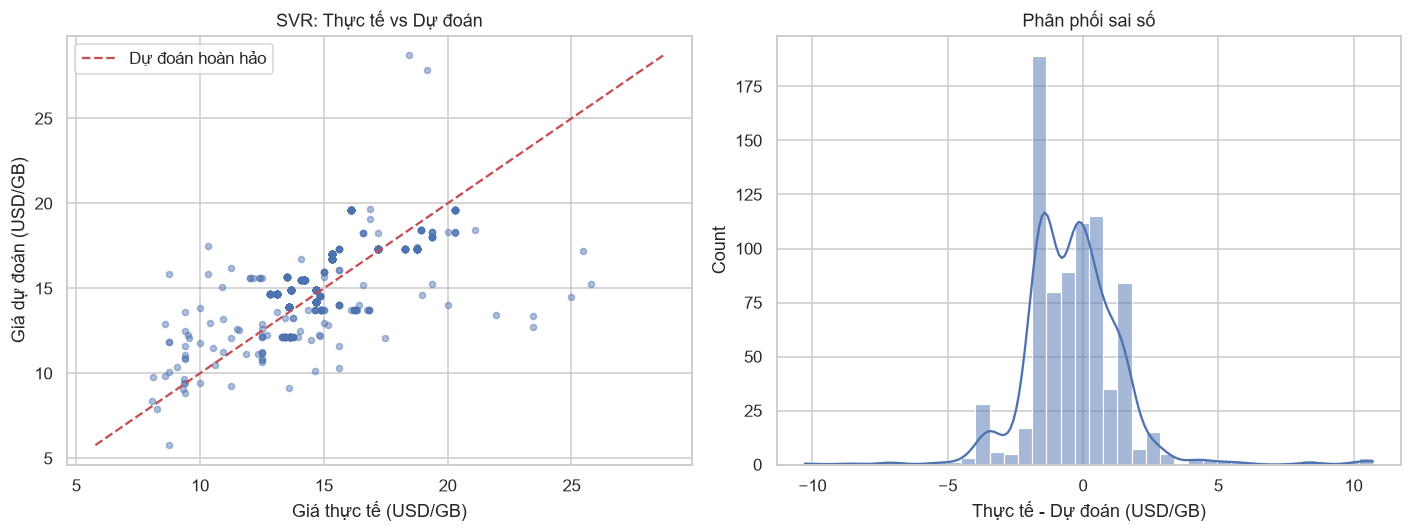

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(y_test, y_pred, alpha=0.45, s=16)
lims = [
    min(float(np.min(y_test)), float(np.min(y_pred))),
    max(float(np.max(y_test)), float(np.max(y_pred)))
]
axes[0].plot(lims, lims, "r--", label="Dự đoán hoàn hảo")
axes[0].set_xlabel("Giá thực tế (USD/GB)")
axes[0].set_ylabel("Giá dự đoán (USD/GB)")
axes[0].set_title("SVR: Thực tế vs Dự đoán")
axes[0].legend()

residuals = y_test.to_numpy() - y_pred
sns.histplot(residuals, bins=40, kde=True, ax=axes[1])
axes[1].set_title("Phân phối sai số")
axes[1].set_xlabel("Thực tế - Dự đoán (USD/GB)")

plt.tight_layout()
plt.savefig(RESULTS_DIR / "02_svr_actual_vs_predicted.png", dpi=120)
plt.show()

## 11. Lưu mô hình và kết quả dự đoán

In [12]:
model_path = RESULTS_DIR / "svr_ram_model.pkl"
joblib.dump(model, model_path)

predictions = eval_df.copy()
predictions.to_csv(RESULTS_DIR / "svr_ram_predictions.csv", index=False)

print("Đã lưu:")
print("-", model_path)
print("-", RESULTS_DIR / "svr_ram_predictions.csv")
print("-", RESULTS_DIR / "svr_metrics_by_source.csv")
print("-", RESULTS_DIR / "02_svr_actual_vs_predicted.png")

Đã lưu:
- d:\DPYTHONSVR\results\svr_ram_model.pkl
- d:\DPYTHONSVR\results\svr_ram_predictions.csv
- d:\DPYTHONSVR\results\svr_metrics_by_source.csv
- d:\DPYTHONSVR\results\02_svr_actual_vs_predicted.png


## 12. Dự đoán giá cho một cấu hình RAM mới
Thay đổi các thông số trong `my_ram` để dự đoán cấu hình khác. Kết quả là USD/GB và ước tính tổng giá kit.

In [13]:
my_ram = pd.DataFrame([{
    "capacity_gb": 32,
    "speed_mhz": 6000,
    "cas_latency": 30,
    "num_sticks": 2,
    "is_sodimm": 0,
    "has_rgb": 1,
    "is_ecc_server": 0,
    "brand": "Corsair",
    "source": "A_retail",
    "condition": "New",
}])

predicted_usd_per_gb = max(float(model.predict(my_ram)[0]), 0)
capacity = float(my_ram["capacity_gb"].iloc[0])
print(f"Dự đoán: {predicted_usd_per_gb:.2f} USD/GB")
print(f"Ước tính kit {capacity:.0f}GB: {predicted_usd_per_gb * capacity:.2f} USD")

Dự đoán: 18.33 USD/GB
Ước tính kit 32GB: 586.67 USD


## Ghi chú khi chạy

1. Đặt **3 file CSV cùng thư mục** với notebook:
   - `ram-price-observations.csv`
   - `ram_pricing_intelligence_2026.csv`
   - `costinflation-ddr5-ram-retail-prices-raw-2026-07-13-to-2026-08-10.csv`
2. Nếu thiếu thư viện, chạy trong một ô:
   ```python
   %pip install numpy pandas matplotlib seaborn scikit-learn joblib
   ```
3. Chọn đúng Python kernel rồi chạy lần lượt từ trên xuống bằng **Run All**.
4. Mô hình được huấn luyện ở mục 8. Phải chạy mục 8 thành công trước mục 9 để tránh lỗi `NotFittedError`.
5. SVR RBF có thể tốn thời gian; notebook giới hạn tối đa 6.000 dòng mẫu và vẫn lấy mẫu từ cả ba nguồn.